# Exploratory Data Analysis

This notebook explores customer characteristics, subscription behaviour,
product usage, support interactions, and churn patterns to identify
potentially useful predictors for churn modelling.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [10]:
BASE_DIR = Path.cwd()

while not (BASE_DIR / "data" / "cleaned").exists() and BASE_DIR != BASE_DIR.parent:
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data" / "cleaned"

accounts = pd.read_csv(DATA_DIR / "ravenstack_accounts_clean.csv")
subscriptions = pd.read_csv(DATA_DIR / "ravenstack_subscriptions_clean.csv")
feature_usage = pd.read_csv(DATA_DIR / "ravenstack_feature_usage_clean.csv")
support_tickets = pd.read_csv(DATA_DIR / "ravenstack_support_tickets_clean.csv")
churn_events = pd.read_csv(DATA_DIR / "ravenstack_churn_events_clean.csv")

In [11]:
datasets = {
    "Accounts": accounts,
    "Subscriptions": subscriptions,
    "Feature Usage": feature_usage,
    "Support Tickets": support_tickets,
    "Churn Events": churn_events
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Accounts: (500, 10)
Subscriptions: (5000, 14)
Feature Usage: (25000, 8)
Support Tickets: (2000, 9)
Churn Events: (600, 9)


In [12]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Duplicates:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())


Accounts
Duplicates: 0
Missing values: 0

Subscriptions
Duplicates: 0
Missing values: 4514

Feature Usage
Duplicates: 0
Missing values: 0

Support Tickets
Duplicates: 0
Missing values: 825

Churn Events
Duplicates: 0
Missing values: 148


In [13]:
subscription_summary = (
    subscriptions
    .groupby("account_id")
    .agg(
        subscription_count=("subscription_id", "count"),
        avg_mrr=("mrr_amount", "mean"),
        total_seats=("seats", "sum"),
        upgrade_count=("upgrade_flag", "sum"),
        downgrade_count=("downgrade_flag", "sum"),
        auto_renew_count=("auto_renew_flag", "sum")
    )
    .reset_index()
)
usage_summary = (
    feature_usage
    .merge(
        subscriptions[["subscription_id", "account_id"]],
        on="subscription_id",
        how="left"
    )
    .groupby("account_id")
    .agg(
        total_usage=("usage_count", "sum"),
        total_usage_duration=("usage_duration_secs", "sum"),
        total_errors=("error_count", "sum"),
        beta_feature_usage=("is_beta_feature", "sum")
    )
    .reset_index()
)

support_summary = (
    support_tickets
    .groupby("account_id")
    .agg(
        total_tickets=("ticket_id", "count"),
        avg_resolution_hours=("resolution_time_hours", "mean"),
        avg_response_minutes=("first_response_time_minutes", "mean"),
        avg_satisfaction=("satisfaction_score", "mean"),
        escalated_tickets=("escalation_flag", "sum")
    )
    .reset_index()
)

churn_summary = (
    churn_events
    .groupby("account_id")
    .agg(
        churn_events=("churn_event_id", "count"),
        total_refund=("refund_amount_usd", "sum"),
        reactivation_count=("is_reactivation", "sum")
    )
    .reset_index()
)

account_data = (
    accounts
    .merge(subscription_summary, on="account_id", how="left")
    .merge(usage_summary, on="account_id", how="left")
    .merge(support_summary, on="account_id", how="left")
    .merge(churn_summary, on="account_id", how="left")
)

account_data.shape

(500, 28)

## Churn Overview

Examine the retained and churned customer distribution to understand
the target balance and establish a baseline for further analysis.

Total Customers: 500
Retained: 390
Churned: 110
Overall Churn Rate: 22.00%


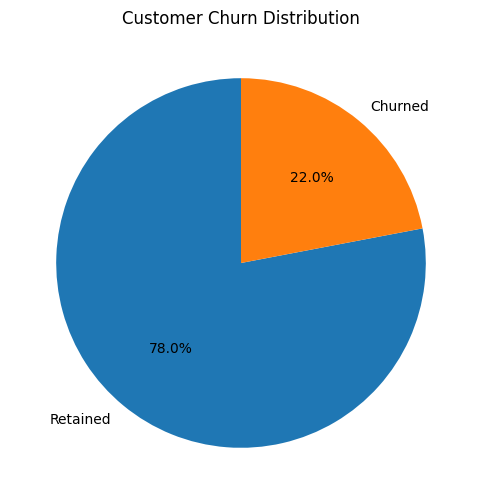

In [14]:
churn_counts = account_data["churn_flag"].value_counts()

print("Total Customers:", len(account_data))
print("Retained:", churn_counts.get(0, 0))
print("Churned:", churn_counts.get(1, 0))

churn_rate = account_data["churn_flag"].mean() * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")

churn_status = (
    account_data["churn_flag"]
    .map({0: "Retained", 1: "Churned"})
    .value_counts()
)

plt.figure(figsize=(6, 6))
plt.pie(
    churn_status.values,
    labels=churn_status.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Customer Churn Distribution")
plt.show()

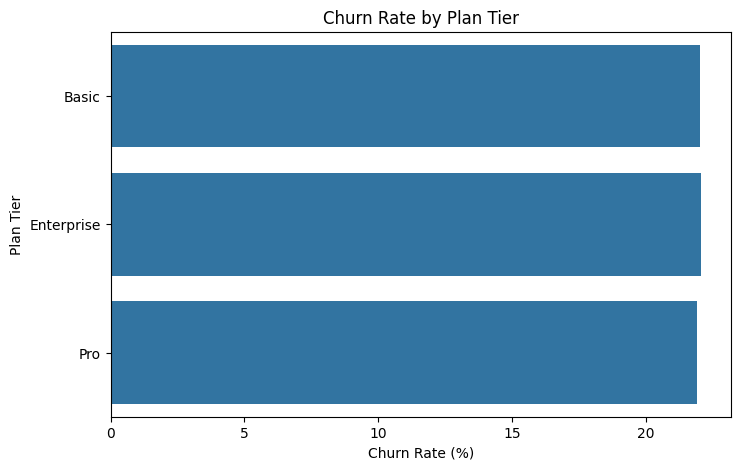

In [15]:
churn_by_plan = (
    account_data
    .groupby("plan_tier")
    .agg(
        customers=("account_id", "count"),
        churned=("churn_flag", "sum"),
        churn_rate=("churn_flag", "mean")
    )
    .reset_index()
)

churn_by_plan["churn_rate"] *= 100

churn_by_plan.sort_values("churn_rate", ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_plan,
    x="churn_rate",
    y="plan_tier"
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Plan Tier")
plt.title("Churn Rate by Plan Tier")
plt.show()

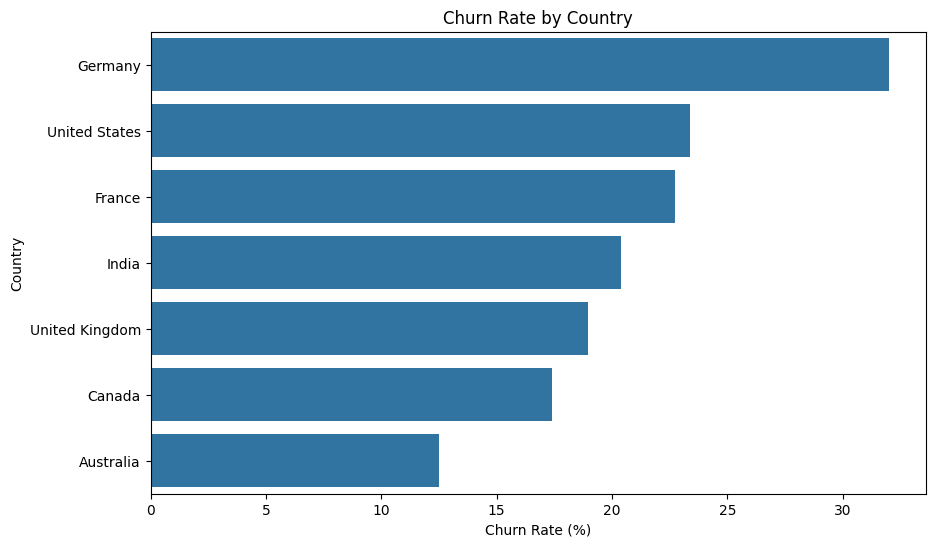

In [16]:
churn_by_country = (
    account_data
    .groupby("country")
    .agg(
        customers=("account_id", "count"),
        churned=("churn_flag", "sum"),
        churn_rate=("churn_flag", "mean")
    )
    .reset_index()
)

churn_by_country["churn_rate"] *= 100

churn_by_country = churn_by_country.sort_values(
    "churn_rate",
    ascending=False
)

churn_by_country

plt.figure(figsize=(10, 6))

sns.barplot(
    data=churn_by_country,
    x="churn_rate",
    y="country"
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Country")
plt.title("Churn Rate by Country")
plt.show()

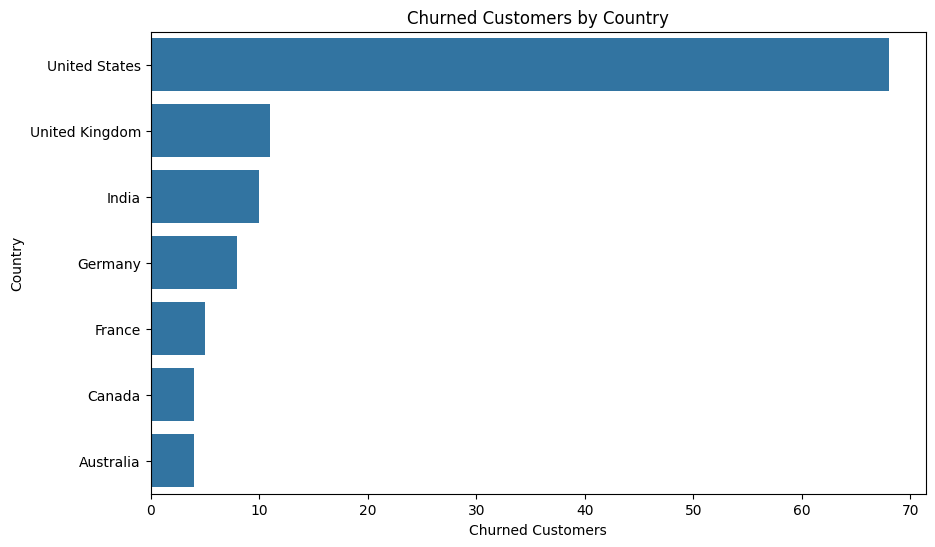

In [17]:
country_volume = churn_by_country.sort_values(
    "churned",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_volume,
    x="churned",
    y="country"
)

plt.xlabel("Churned Customers")
plt.ylabel("Country")
plt.title("Churned Customers by Country")
plt.show()

In [18]:
# Convert all date columns to datetime
accounts["signup_date"] = pd.to_datetime(accounts["signup_date"])
subscriptions["start_date"] = pd.to_datetime(subscriptions["start_date"])
subscriptions["end_date"] = pd.to_datetime(subscriptions["end_date"])
feature_usage["usage_date"] = pd.to_datetime(feature_usage["usage_date"])
support_tickets["submitted_at"] = pd.to_datetime(support_tickets["submitted_at"])
support_tickets["closed_at"] = pd.to_datetime(support_tickets["closed_at"])
churn_events["churn_date"] = pd.to_datetime(churn_events["churn_date"])

# Find the latest date in the datasets
observation_end = max(
    feature_usage["usage_date"].max(),
    support_tickets["submitted_at"].max(),
    subscriptions["end_date"].dropna().max()
)

print("Observation end date:", observation_end)

Observation end date: 2024-12-31 00:00:00


## Customer Behaviour and Churn

Compare usage, tenure, subscription changes, and support interactions
between retained and churned customers to identify behavioural patterns.

In [19]:
# Create one churn date per account
account_churn_date = (
    churn_events
    .groupby("account_id")["churn_date"]
    .min()
    .reset_index()
)

# Remove any old churn-date columns from account_data
account_data = account_data.drop(
    columns=["churn_date", "churn_date_x", "churn_date_y"],
    errors="ignore"
)

# Merge clean churn date
account_data = account_data.merge(
    account_churn_date,
    on="account_id",
    how="left"
)

# Ensure date types are correct
account_data["churn_date"] = pd.to_datetime(account_data["churn_date"])
account_data["signup_date"] = pd.to_datetime(account_data["signup_date"])

# Calculate tenure end
account_data["tenure_end"] = account_data["churn_date"].fillna(
    pd.Timestamp(observation_end)
)

# Calculate tenure
account_data["tenure_days"] = (
    account_data["tenure_end"] -
    account_data["signup_date"]
).dt.days

account_data["tenure_months"] = (
    account_data["tenure_days"] / 30.44
)

# Create tenure groups
account_data["tenure_group"] = pd.cut(
    account_data["tenure_months"],
    bins=[0, 6, 12, np.inf],
    labels=["0–6 Months", "6–12 Months", "1+ Years"],
    right=False
)

print(account_data["tenure_group"].value_counts().sort_index())

# Verify
print(
    account_data[
        [
            "account_id",
            "signup_date",
            "churn_date",
            "tenure_months",
            "tenure_group"
        ]
    ].head(10)
)

print("\nAccount_data shape:", account_data.shape)
print("\nTenure groups:")
print(account_data["tenure_group"].value_counts().sort_index())

tenure_group
0–6 Months     305
6–12 Months    102
1+ Years        93
Name: count, dtype: int64
  account_id signup_date churn_date  tenure_months tenure_group
0   A-2e4581  2024-10-16 2024-11-23       1.248357   0–6 Months
1   A-43a9e3  2023-08-17        NaT      16.491459     1+ Years
2   A-0a282f  2024-08-27 2024-10-06       1.314060   0–6 Months
3   A-1f0ac7  2023-08-27 2024-11-08      14.421813     1+ Years
4   A-ce550d  2024-10-27 2024-12-28       2.036794   0–6 Months
5   A-1b9609  2023-10-12 2024-01-02       2.693824   0–6 Months
6   A-a0ca4e  2024-03-08        NaT       9.789750  6–12 Months
7   A-e5d6ab  2023-04-15 2023-04-24       0.295664   0–6 Months
8   A-7dacce  2024-09-10 2024-09-18       0.262812   0–6 Months
9   A-10b8da  2023-05-08        NaT      19.809461     1+ Years

Account_data shape: (500, 33)

Tenure groups:
tenure_group
0–6 Months     305
6–12 Months    102
1+ Years        93
Name: count, dtype: int64


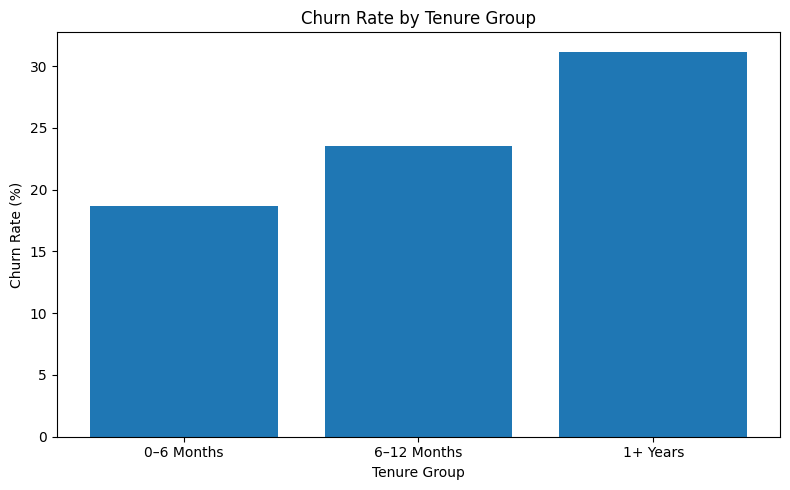

In [20]:
churn_by_tenure = (
    account_data
    .groupby("tenure_group", observed=True)
    .agg(
        customers=("account_id", "count"),
        churned=("churn_flag", "sum")
    )
    .reset_index()
)

churn_by_tenure["churn_rate"] = (
    churn_by_tenure["churned"] /
    churn_by_tenure["customers"] * 100
)

churn_by_tenure


plt.figure(figsize=(8, 5))

plt.bar(
    churn_by_tenure["tenure_group"],
    churn_by_tenure["churn_rate"]
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

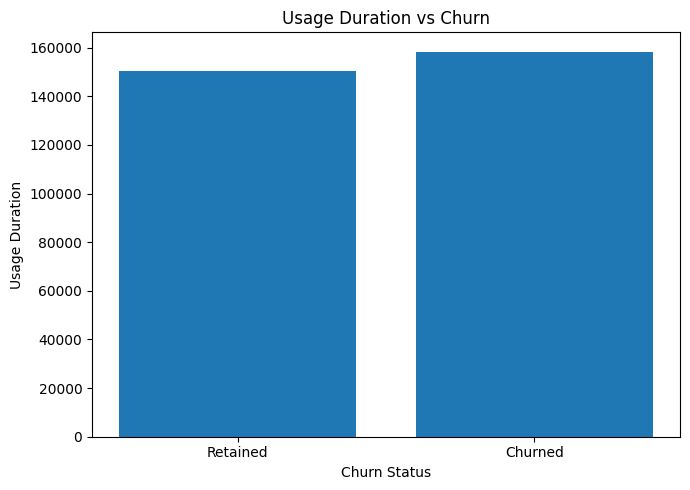

In [21]:
behavior_analysis = (
    account_data
    .groupby("churn_flag")
    .agg(
        avg_feature_usage=("total_usage", "mean"),
        avg_usage_duration=("total_usage_duration", "mean"),
        avg_support_satisfaction=("avg_satisfaction", "mean")
    )
    .reset_index()
)

behavior_analysis["churn_status"] = behavior_analysis["churn_flag"].map({
    0: "Retained",
    1: "Churned"
})

behavior_analysis

# selected_metric = "avg_feature_usage"
# selected_label = "Feature Usage"

selected_metric = "avg_usage_duration"
selected_label = "Usage Duration"

# selected_metric = "avg_support_satisfaction"
# selected_label = "Support Satisfaction"

plt.figure(figsize=(7, 5))

plt.bar(
    behavior_analysis["churn_status"],
    behavior_analysis[selected_metric]
)

plt.title(f"{selected_label} vs Churn")
plt.xlabel("Churn Status")
plt.ylabel(selected_label)
plt.tight_layout()
plt.show()

In [22]:
country_tenure = (
    account_data
    .groupby(["country", "tenure_group"], observed=True)
    .agg(
        customers=("account_id", "count"),
        churned=("churn_flag", "sum")
    )
    .reset_index()
)

country_tenure["churn_rate"] = (
    country_tenure["churned"] /
    country_tenure["customers"] * 100
)

country_tenure_pivot = country_tenure.pivot(
    index="country",
    columns="tenure_group",
    values="churn_rate"
)

country_tenure_pivot

tenure_group,0–6 Months,6–12 Months,1+ Years
country,,,
Australia,11.111111,10.000000,25.000000
Canada,14.285714,25.000000,20.000000
France,23.076923,33.333333,0.000000
Germany,50.000000,20.000000,28.571429
India,13.333333,28.571429,33.333333
United Kingdom,16.216216,18.181818,30.000000
United States,19.459459,25.925926,34.615385


In [23]:
auto_renew_analysis = (
    account_data
    .groupby(["auto_renew_count", "churn_flag"])
    .agg(
        customers=("account_id", "count")
    )
    .reset_index()
)

auto_renew_analysis["auto_renew_status"] = auto_renew_analysis[
    "auto_renew_count"
].apply(
    lambda x: "Auto-Renew" if x > 0 else "Not Auto-Renew"
)

auto_renew_analysis["churn_status"] = auto_renew_analysis[
    "churn_flag"
].map({
    0: "Retained",
    1: "Churned"
})

auto_renew_analysis

,auto_renew_count,churn_flag,customers,auto_renew_status,churn_status
0,1,0,2,Auto-Renew,Retained
1,2,0,3,Auto-Renew,Retained
2,2,1,1,Auto-Renew,Churned
3,3,0,17,Auto-Renew,Retained
4,3,1,4,Auto-Renew,Churned
5,4,0,29,Auto-Renew,Retained
6,4,1,4,Auto-Renew,Churned
7,5,0,35,Auto-Renew,Retained
8,5,1,7,Auto-Renew,Churned
9,6,0,42,Auto-Renew,Retained


In [24]:
auto_renew_analysis = (
    account_data
    .groupby(["auto_renew_count", "churn_flag"])
    .agg(
        customers=("account_id", "count")
    )
    .reset_index()
)

auto_renew_analysis["auto_renew_status"] = auto_renew_analysis[
    "auto_renew_count"
].apply(
    lambda x: "Auto-Renew" if x > 0 else "Not Auto-Renew"
)

auto_renew_analysis["churn_status"] = auto_renew_analysis[
    "churn_flag"
].map({
    0: "Retained",
    1: "Churned"
})

auto_renew_analysis

,auto_renew_count,churn_flag,customers,auto_renew_status,churn_status
0,1,0,2,Auto-Renew,Retained
1,2,0,3,Auto-Renew,Retained
2,2,1,1,Auto-Renew,Churned
3,3,0,17,Auto-Renew,Retained
4,3,1,4,Auto-Renew,Churned
5,4,0,29,Auto-Renew,Retained
6,4,1,4,Auto-Renew,Churned
7,5,0,35,Auto-Renew,Retained
8,5,1,7,Auto-Renew,Churned
9,6,0,42,Auto-Renew,Retained


In [25]:
subscription_changes = (
    account_data
    .groupby("churn_flag")
    .agg(
        avg_upgrades=("upgrade_count", "mean"),
        avg_downgrades=("downgrade_count", "mean")
    )
    .reset_index()
)

subscription_changes["churn_status"] = subscription_changes[
    "churn_flag"
].map({
    0: "Retained",
    1: "Churned"
})

subscription_changes

,churn_flag,avg_upgrades,avg_downgrades,churn_status
0,0,1.058974,0.438462,Retained
1,1,1.054545,0.427273,Churned


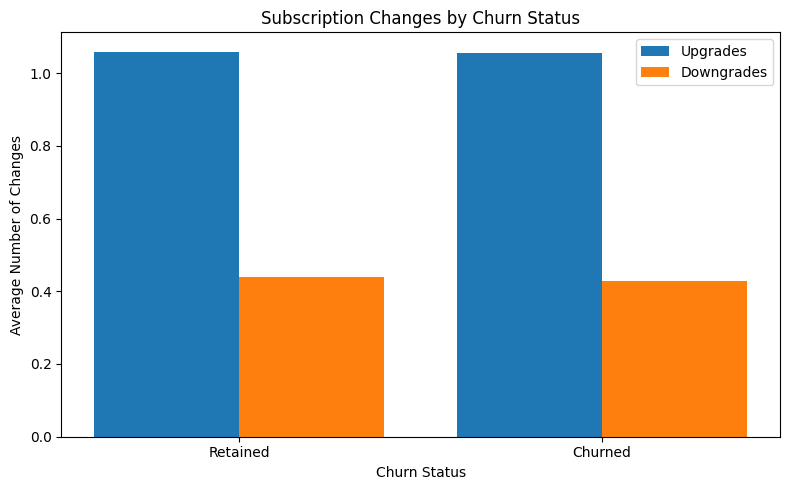

In [26]:
x = range(len(subscription_changes))

plt.figure(figsize=(8, 5))

plt.bar(
    [i - 0.2 for i in x],
    subscription_changes["avg_upgrades"],
    width=0.4,
    label="Upgrades"
)

plt.bar(
    [i + 0.2 for i in x],
    subscription_changes["avg_downgrades"],
    width=0.4,
    label="Downgrades"
)

plt.xticks(
    list(x),
    subscription_changes["churn_status"]
)

plt.title("Subscription Changes by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Number of Changes")
plt.legend()

plt.tight_layout()
plt.show()

## Feature Selection

Candidate features were selected based on business relevance,
availability, and their potential to describe customer behaviour.
The final feature set is evaluated in the classification notebooks.

In [27]:
candidate_features = [
    "plan_tier",
    "industry",
    "country",
    "seats",
    "is_trial",
    "avg_mrr",
    "upgrade_count",
    "downgrade_count",
    "auto_renew_count",
    "total_usage",
    "total_usage_duration",
    "total_errors",
    "beta_feature_usage",
    "total_tickets",
    "avg_resolution_hours",
    "avg_response_minutes",
    "avg_satisfaction",
    "escalated_tickets",
    "tenure_months"
]

leakage_features = [
    "churn_date",
    "reason_code",
    "refund_amount_usd",
    "feedback_text"
]

print("Potential model features:")
print(candidate_features)

print("\nFeatures to exclude because of leakage:")
print(leakage_features)

Potential model features:
['plan_tier', 'industry', 'country', 'seats', 'is_trial', 'avg_mrr', 'upgrade_count', 'downgrade_count', 'auto_renew_count', 'total_usage', 'total_usage_duration', 'total_errors', 'beta_feature_usage', 'total_tickets', 'avg_resolution_hours', 'avg_response_minutes', 'avg_satisfaction', 'escalated_tickets', 'tenure_months']

Features to exclude because of leakage:
['churn_date', 'reason_code', 'refund_amount_usd', 'feedback_text']


In [28]:
# These missing values mean the account had no related records
zero_fill_columns = [
    "total_tickets",
    "avg_resolution_hours",
    "avg_response_minutes",
    "escalated_tickets",
    "churn_events",
    "total_refund",
    "reactivation_count"
]

account_data[zero_fill_columns] = (
    account_data[zero_fill_columns].fillna(0)
)

print("Missing values after structural handling:")
print(
    account_data.isna()
    .sum()
    .loc[lambda x: x > 0]
)

Missing values after structural handling:
avg_satisfaction     34
churn_date          148
dtype: int64


In [29]:
print("Shape:", account_data.shape)

print("\nDuplicate rows:", account_data.duplicated().sum())

print("\nMissing values:")
print(
    account_data.isna()
    .sum()
    .loc[lambda x: x > 0]
)

print("\nChurn distribution:")
print(account_data["churn_flag"].value_counts())

Shape: (500, 33)

Duplicate rows: 0

Missing values:
avg_satisfaction     34
churn_date          148
dtype: int64

Churn distribution:
churn_flag
0    390
1    110
Name: count, dtype: int64


In [30]:
# Round average and tenure columns to 2 decimal places
round_columns = [
    "avg_mrr",
    "avg_resolution_hours",
    "avg_response_minutes",
    "avg_satisfaction",
    "tenure_months"
]

account_data[round_columns] = account_data[round_columns].round(2)

print(account_data[round_columns].head())

   avg_mrr  avg_resolution_hours  avg_response_minutes  avg_satisfaction  \
0  1260.30                 23.00                 91.00              3.00   
1  1250.50                 38.00                 73.33              4.00   
2  1219.07                 43.67                 63.67              4.67   
3  1325.00                 29.00                174.00               NaN   
4  5417.89                 42.29                107.86              3.80   

   tenure_months  
0           1.25  
1          16.49  
2           1.31  
3          14.42  
4           2.04  


In [31]:
# account_data.to_csv(
#     "account_data.csv",
#     index=False
# )

print("Saved: account_data.csv")

Saved: account_data.csv


## EDA Summary

The analysis provides an initial understanding of customer churn
and informs feature selection. These associations are exploratory
and do not, by themselves, establish causation.